# Step 4: financial model, valuation, risk scenarios and KPI test

Two markets, one structure: Singapore and Korea.

1. **Unit economics** back-solved from the shelf price: retailer margin, importer margin and handling set the CIF price the exporter can charge; exporter costs (ex-works, freight, insurance) and trade spend leave the net contribution per can.
2. **Five-year cash flow**: category volume (grown at a scenario rate) times the share ramp (scaled by a scenario multiplier) times net contribution, less fixed costs and a one-off set-up cost in year 0.
3. **Valuation**: NPV at the discount rate, with a terminal value on year-5 cash flow, payback year and peak funding.
4. **Scenarios**: base, bull and bear, from the growth and share ranges in step 3 and `assumptions.json`.
5. **Sensitivity**: a tornado on NPV, one input at a time between its low and high values.
6. **KPI test** against the thresholds in `00_kpi_thresholds_and_risk_register.md`. K4 to K6 are not testable in the model and are shown as open.

All inputs come from `data/assumptions.json`. Status of each input is recorded there. Korea's 0% tariff is a placeholder until the gate run resolves it.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
A = json.loads((HERE / "data" / "assumptions.json").read_text(encoding="utf-8"))
COMMON = {k: v["value"] for k, v in A["common"].items() if k in ("wacc", "terminal_growth")}
RAMP = A["common"]["ramp_share_base"]["value"]
MULT = {"base": 1.0, "bull": A["common"]["bull_multiplier"]["value"], "bear": A["common"]["bear_multiplier"]["value"]}
# Category growth per year. Singapore: step 3 flavoured-lane trend (0.0%, interval -1.8% to +1.8%).
# Korea: vendor MarketLine carbonates volume CAGR 2019 to 2024 (3.7%); bull 6% and bear 0% are judgement.
GROWTH = {
    "singapore": {"base": 0.0, "bull": 0.018, "bear": -0.018},
    "korea": {"base": 0.037, "bull": 0.060, "bear": 0.0},
}
NPV_CHECK_SGD = 1_000_000  # K8 threshold, set in step 0 for user confirmation

def params(market, overrides=None):
    p = {k: v["value"] for k, v in A[market].items()}
    p.setdefault("usd_sgd", A["singapore"]["usd_sgd"]["value"])  # shared FX rate for the Korea case
    p.update(overrides or {})
    return p

print("Singapore base inputs:", len(params("singapore")), "| Korea base inputs:", len(params("korea")))

Singapore base inputs: 20 | Korea base inputs: 18


## 1. Unit economics per can (back-solved from the shelf price)

In [2]:
def unit_sg(p):
    retail_ex = p["shelf_price_sgd_per_can"] / (1 + p["gst_rate"])
    buy = retail_ex * (1 - p["retailer_margin"])
    imp_cost = buy * (1 - p["importer_margin"])
    # ceiling: what the importer can pay after its handling and the BCRS producer fee; deposit is pass-through
    ceiling = imp_cost - p["importer_handling_sgd_per_can"] - p["bcrs_producer_fee_sgd_per_can"] - p["bcrs_deposit_sgd_per_can"]
    # realised basis: category unit value bracket (Comtrade), importer carries its own costs
    cif = p["cif_realised_sgd_per_can"] if p.get("cif_basis") == "realised" else ceiling
    freight = p["freight_20ft_usd"] / (p["cartons_per_20ft"] * p["cans_per_carton"]) * p["usd_sgd"]
    cost = p["exworks_usd_per_can"] * p["usd_sgd"] + freight + p["insurance_sgd_per_can"]
    gross = cif - cost
    net = gross - p["trade_spend_share"] * cif
    return {"ccy": "SGD", "fx_to_sgd": 1.0, "cif": cif, "exporter_cost": cost, "gross": gross, "net": net, "net_pct": net / cif}

def unit_kr(p):
    retail_ex = p["shelf_price_krw_per_can"] / (1 + p["vat_rate"])
    buy = retail_ex * (1 - p["retailer_margin"])
    imp_cost = buy * (1 - p["importer_margin"])
    ceiling = (imp_cost - p["importer_handling_krw_per_can"]) / (1 + p["tariff_rate"])
    # realised basis: exporter sells at the observed Thai unit value, and the importer absorbs the tariff
    cif = p["cif_realised_krw_per_can"] if p.get("cif_basis") == "realised" else ceiling
    freight = p["freight_20ft_usd"] / (p["cartons_per_20ft"] * 24) * p["usd_krw"]
    cost = p["exworks_usd_per_can"] * p["usd_krw"] + freight + p["insurance_krw_per_can"]
    gross = cif - cost
    net = gross - p["trade_spend_share"] * cif - p.get("sugar_levy_krw_per_can", 0.0)
    return {"ccy": "KRW", "fx_to_sgd": p["usd_sgd"] / p["usd_krw"], "cif": cif, "exporter_cost": cost, "gross": gross, "net": net, "net_pct": net / cif}

unit_rows = []
for mkt, fn in [("singapore", unit_sg), ("korea", unit_kr)]:
    u = fn(params(mkt, {"cif_basis": "realised"}))  # base case uses the realised basis in both markets
    unit_rows.append({"market": mkt, "ccy": u["ccy"], "cif_per_can": u["cif"], "exporter_cost_per_can": u["exporter_cost"],
                      "gross_per_can": u["gross"], "net_per_can": u["net"], "net_pct_of_cif": u["net_pct"]})
unit_df = pd.DataFrame(unit_rows)
unit_df.round(3)

,market,ccy,cif_per_can,exporter_cost_per_can,gross_per_can,net_per_can,net_pct_of_cif
0,singapore,SGD,0.478,0.342,0.135,0.088,0.183
1,korea,KRW,528.000,386.875,141.125,88.325,0.167


## 2. Five-year cash flow, valuation and KPI metrics

In [3]:
# CIF basis by scenario. Korea: base uses the realised Thai unit value; bull uses the back-solved importer ceiling;
# bear uses the low end of the realised range. Singapore: ceiling until a Thai unit value for Singapore is computed.
CIF_CASE = {
    "korea": {"base": ("realised", None), "bull": ("ceiling", None), "bear": ("realised", 450)},
    "singapore": {"base": ("realised", None), "bull": ("ceiling", None), "bear": ("realised", 0.380)},
}

def run_case(market, growth_case="base", mult_case="base", overrides=None, years=5):
    basis, cif_override = CIF_CASE[market][growth_case]
    ov = dict(overrides or {})
    ov.setdefault("cif_basis", basis)
    if cif_override is not None:
        key = "cif_realised_krw_per_can" if market == "korea" else "cif_realised_sgd_per_can"
        ov.setdefault(key, cif_override)
    overrides = ov
    p = params(market, overrides)
    u = unit_sg(p) if market == "singapore" else unit_kr(p)
    setup = p["one_off_setup_sgd"] if market == "singapore" else p["one_off_setup_krw"]
    fixed = p["fixed_cost_sgd_per_year"] if market == "singapore" else p["fixed_cost_krw_per_year"]
    g = (overrides or {}).get("growth", GROWTH[market][growth_case])
    cat0 = p["category_volume_cans"]
    wacc, tg = COMMON["wacc"], COMMON["terminal_growth"]
    rows = []
    for y in range(1, years + 1):
        cat = cat0 * (1 + g) ** y
        share = RAMP[y - 1] * MULT[mult_case] * p.get("ramp_multiplier", 1.0)
        cans = share * cat
        contrib = cans * u["net"]
        cash = contrib - fixed
        rows.append({"year": y, "category_cans": cat, "share": share, "cans": cans,
                     "net_contribution": contrib, "fixed_cost": fixed, "cash": cash})
    cf = pd.DataFrame(rows)
    pv = float(np.sum(cf["cash"] / (1 + wacc) ** cf["year"]))
    cash5 = float(cf["cash"].iloc[-1])
    tv_pv = cash5 * (1 + tg) / (wacc - tg) / (1 + wacc) ** years if cash5 > 0 else 0.0
    npv_local = -setup + pv + tv_pv
    cum = np.concatenate([[-setup], np.cumsum(cf["cash"].values) - setup])
    cf["cum_cash"] = cum[1:]
    payback = next((int(y) for y, c in zip(cf["year"], cf["cum_cash"]) if c >= 0), None)
    peak_local = -min(cum.min(), 0.0)
    fx = u["fx_to_sgd"]
    cat3 = cat0 * (1 + g) ** 3
    # no break-even when net contribution is zero or negative
    breakeven_cans = fixed / u["net"] if u["net"] > 0 else float("inf")
    summary = {
        "market": market, "growth_case": growth_case, "mult_case": mult_case,
        "net_pct_of_cif": u["net_pct"], "net_per_can_local": u["net"], "ccy": u["ccy"],
        "breakeven_cans": breakeven_cans, "breakeven_share_year3": breakeven_cans / cat3,
        "year3_share": float(cf.loc[cf["year"] == 3, "share"].iloc[0]),
        "npv_sgd": npv_local * fx, "payback_year": payback,
        "peak_funding_sgd": peak_local * fx,
        "year5_cans": float(cf["cans"].iloc[-1]),
    }
    return cf, summary

summaries, flows = [], {}
for mkt in ["singapore", "korea"]:
    for gc in ["base", "bull", "bear"]:
        mc = gc  # scenario keeps growth and share multiplier together
        cf, s = run_case(mkt, gc, mc)
        summaries.append(s)
        flows[(mkt, gc)] = cf
summary_df = pd.DataFrame(summaries)
summary_df.round(3)

,market,growth_case,mult_case,net_pct_of_cif,net_per_can_local,ccy,breakeven_cans,breakeven_share_year3,year3_share,npv_sgd,payback_year,peak_funding_sgd,year5_cans
0,singapore,base,base,0.183,0.088,SGD,5.131129e+06,0.012,0.006,-9.974746e+05,NaN,1262160.400,4.120000e+06
1,singapore,bull,bull,0.336,0.204,SGD,2.203405e+06,0.005,0.011,7.665824e+06,3.0,355817.291,8.107904e+06
2,singapore,bear,bear,-0.001,-0.001,SGD,inf,inf,0.002,-1.683610e+06,NaN,2312229.569,1.504924e+06
3,korea,base,base,0.167,88.325,KRW,5.660911e+06,0.009,0.006,-1.002698e+05,NaN,994214.538,7.075315e+06
4,korea,bull,bull,0.457,398.580,KRW,1.254455e+06,0.002,0.011,3.446881e+07,2.0,129365.685,1.421196e+07
5,korea,bear,bear,0.040,18.125,KRW,2.758621e+07,0.047,0.002,-1.774647e+06,NaN,2419568.019,2.360000e+06


In [4]:
base_rows = {}
for mkt in ["singapore", "korea"]:
    cf = flows[(mkt, "base")].copy()
    cf.insert(0, "market", mkt)
    base_rows[mkt] = cf
pd.concat(base_rows.values()).round(0)

,market,year,category_cans,share,cans,net_contribution,fixed_cost,cash,cum_cash
0,singapore,1,412000000.0,0.0,412000.0,36132.0,450000,-413868.0,-4.738680e+05
1,singapore,2,412000000.0,0.0,1236000.0,108397.0,450000,-341603.0,-8.154700e+05
2,singapore,3,412000000.0,0.0,2472000.0,216794.0,450000,-233206.0,-1.048676e+06
3,singapore,4,412000000.0,0.0,3708000.0,325192.0,450000,-124808.0,-1.173484e+06
4,singapore,5,412000000.0,0.0,4120000.0,361324.0,450000,-88676.0,-1.262160e+06
0,korea,1,611830000.0,0.0,611830.0,54039885.0,500000000,-445960115.0,-5.259601e+08
1,korea,2,634467710.0,0.0,1903403.0,168118081.0,500000000,-331881919.0,-8.578420e+08
2,korea,3,657943015.0,0.0,3947658.0,348676901.0,500000000,-151323099.0,-1.009165e+09
3,korea,4,682286907.0,0.0,6140582.0,542366919.0,500000000,42366919.0,-9.667982e+08
4,korea,5,707531522.0,0.0,7075315.0,624927217.0,500000000,124927217.0,-8.418710e+08


## 3. KPI test (step 0 thresholds)

In [5]:
def kpi_table(summary_frame):
    out = []
    for _, s in summary_frame.iterrows():
        k1 = s["net_pct_of_cif"] >= 0.20
        k2 = s["breakeven_share_year3"] <= 0.010
        k3 = s["year3_share"] >= s["breakeven_share_year3"]
        k7 = s["npv_sgd"] > 0
        k8 = s["peak_funding_sgd"] <= NPV_CHECK_SGD
        out.append({
            "market": s["market"], "scenario": s["growth_case"],
            "K1_net_pct_at_least_20": ("pass" if k1 else "fail") + f" ({s['net_pct_of_cif']:.0%})",
            "K2_breakeven_share_at_most_1pct": ("pass" if k2 else "fail") + f" ({s['breakeven_share_year3']:.2%})",
            "K3_year3_share_at_least_breakeven": ("pass" if k3 else "fail") + f" ({s['year3_share']:.2%} vs {s['breakeven_share_year3']:.2%})",
            "K4_listing": "open (not modelled)", "K5_pilot_velocity": "open (not modelled)", "K6_regulatory": "open (resolution run)",
            "K7_npv_positive": ("pass" if k7 else "fail") + f" (SGD {s['npv_sgd']/1e6:.2f}m)",
            "K8_peak_funding_at_most_1m_sgd": ("pass" if k8 else "fail") + f" (SGD {s['peak_funding_sgd']/1e6:.2f}m)",
        })
    return pd.DataFrame(out)

kpi = kpi_table(summary_df)
kpi

,market,scenario,K1_net_pct_at_least_20,K2_breakeven_share_at_most_1pct,K3_year3_share_at_least_breakeven,K4_listing,K5_pilot_velocity,K6_regulatory,K7_npv_positive,K8_peak_funding_at_most_1m_sgd
0,singapore,base,fail (18%),fail (1.25%),fail (0.60% vs 1.25%),open (not modelled),open (not modelled),open (resolution run),fail (SGD -1.00m),fail (SGD 1.26m)
1,singapore,bull,pass (34%),pass (0.51%),pass (1.08% vs 0.51%),open (not modelled),open (not modelled),open (resolution run),pass (SGD 7.67m),pass (SGD 0.36m)
2,singapore,bear,fail (-0%),fail (inf%),fail (0.24% vs inf%),open (not modelled),open (not modelled),open (resolution run),fail (SGD -1.68m),fail (SGD 2.31m)
3,korea,base,fail (17%),pass (0.86%),fail (0.60% vs 0.86%),open (not modelled),open (not modelled),open (resolution run),fail (SGD -0.10m),pass (SGD 0.99m)
4,korea,bull,pass (46%),pass (0.18%),pass (1.08% vs 0.18%),open (not modelled),open (not modelled),open (resolution run),pass (SGD 34.47m),pass (SGD 0.13m)
5,korea,bear,fail (4%),fail (4.68%),fail (0.24% vs 4.68%),open (not modelled),open (not modelled),open (resolution run),fail (SGD -1.77m),fail (SGD 2.42m)


## 4. Sensitivity (tornado) on NPV, base scenario

In [6]:
TORNADO = {
    "singapore": ["shelf_price_sgd_per_can", "retailer_margin", "importer_margin", "exworks_usd_per_can", "freight_20ft_usd",
                  "cartons_per_20ft", "trade_spend_share", "fixed_cost_sgd_per_year", "usd_sgd",
                  "bcrs_deposit_sgd_per_can", "bcrs_producer_fee_sgd_per_can", "importer_handling_sgd_per_can", "one_off_setup_sgd",
                  "category_volume_cans", "cif_realised_sgd_per_can"],
    "korea": ["shelf_price_krw_per_can", "retailer_margin", "importer_margin", "exworks_usd_per_can", "freight_20ft_usd",
              "cartons_per_20ft", "trade_spend_share", "fixed_cost_krw_per_year", "usd_krw", "tariff_rate",
              "importer_handling_krw_per_can", "one_off_setup_krw", "category_volume_cans", "cif_realised_krw_per_can",
              "sugar_levy_krw_per_can"],
}
GROWTH_RANGE = {"singapore": (GROWTH["singapore"]["bear"], GROWTH["singapore"]["bull"]),
                "korea": (GROWTH["korea"]["bear"], GROWTH["korea"]["bull"])}

def npv_with(market, key, value):
    return run_case(market, "base", "base", overrides={key: value})[1]["npv_sgd"]

tor_rows = []
for mkt, keys in TORNADO.items():
    base_npv = summary_df.query("market == @mkt and growth_case == 'base'")["npv_sgd"].iloc[0]
    for key in keys:
        lo, hi = A[mkt][key]["low"], A[mkt][key]["high"]
        n_lo, n_hi = npv_with(mkt, key, lo), npv_with(mkt, key, hi)
        tor_rows.append({"market": mkt, "input": key, "low": lo, "high": hi,
                         "npv_at_low_sgd": n_lo, "npv_at_high_sgd": n_hi,
                         "swing_sgd": abs(n_hi - n_lo), "base_npv_sgd": base_npv})
    # share ramp and category growth are not low/high inputs in assumptions.json
    n_lo = run_case(mkt, "base", "base", overrides={"ramp_multiplier": 0.5})[1]["npv_sgd"]
    n_hi = run_case(mkt, "base", "base", overrides={"ramp_multiplier": 1.5})[1]["npv_sgd"]
    tor_rows.append({"market": mkt, "input": "share ramp (x0.5 / x1.5)", "low": 0.5, "high": 1.5,
                     "npv_at_low_sgd": n_lo, "npv_at_high_sgd": n_hi, "swing_sgd": abs(n_hi - n_lo), "base_npv_sgd": base_npv})
    g_lo, g_hi = GROWTH_RANGE[mkt]
    n_lo = run_case(mkt, "base", "base", overrides={"growth": g_lo})[1]["npv_sgd"]
    n_hi = run_case(mkt, "base", "base", overrides={"growth": g_hi})[1]["npv_sgd"]
    tor_rows.append({"market": mkt, "input": "category growth (bear / bull)", "low": g_lo, "high": g_hi,
                     "npv_at_low_sgd": n_lo, "npv_at_high_sgd": n_hi, "swing_sgd": abs(n_hi - n_lo), "base_npv_sgd": base_npv})

tornado = pd.DataFrame(tor_rows).sort_values(["market", "swing_sgd"], ascending=[True, False])
tornado.round(3)

,market,input,low,high,npv_at_low_sgd,npv_at_high_sgd,swing_sgd,base_npv_sgd
30,korea,cif_realised_krw_per_can,4.500000e+02,8.050000e+02,-1626104.008,1.209488e+07,1.372098e+07,-100269.805
20,korea,exworks_usd_per_can,1.500000e-01,3.000000e-01,3201665.511,-2.442662e+06,5.644328e+06,-100269.805
32,korea,share ramp (x0.5 / x1.5),5.000000e-01,1.500000e+00,-1298000.102,2.060052e+06,3.358052e+06,-100269.805
21,korea,freight_20ft_usd,1.200000e+03,2.200000e+03,1825859.129,-9.257536e+05,2.751613e+06,-100269.805
24,korea,fixed_cost_krw_per_year,3.500000e+08,7.000000e+08,1202359.744,-1.451774e+06,2.654134e+06,-100269.805
23,korea,trade_spend_share,5.000000e-02,2.000000e-01,1191153.785,-1.406843e+06,2.597997e+06,-100269.805
22,korea,cartons_per_20ft,8.000000e+02,1.200000e+03,-1078187.811,7.710742e+05,1.849262e+06,-100269.805
29,korea,category_volume_cans,4.000000e+08,7.000000e+08,-1099923.557,7.052739e+05,1.805197e+06,-100269.805
25,korea,usd_krw,1.300000e+03,1.450000e+03,604943.107,-1.017884e+06,1.622827e+06,-100269.805
33,korea,category growth (bear / bull),0.000000e+00,6.000000e-02,-773269.364,3.668313e+05,1.140101e+06,-100269.805


## 5. Outputs and charts

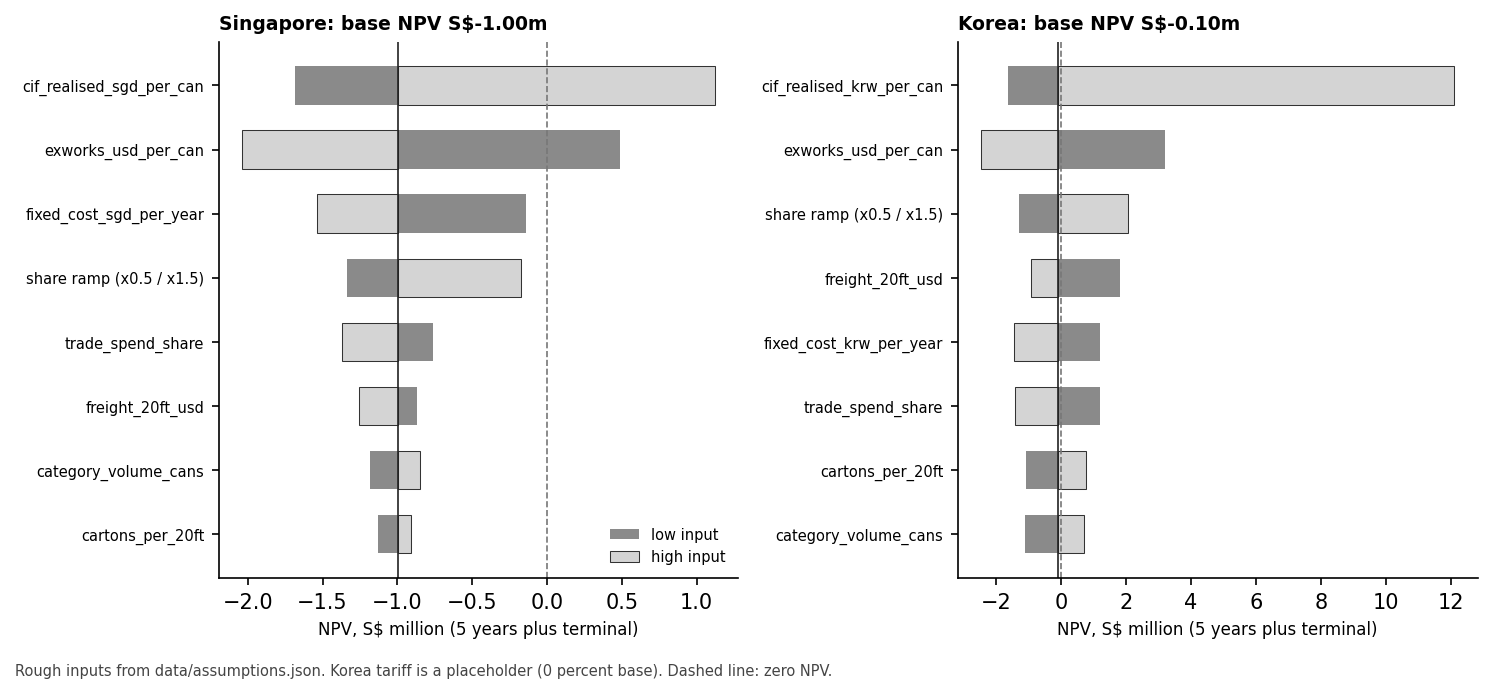

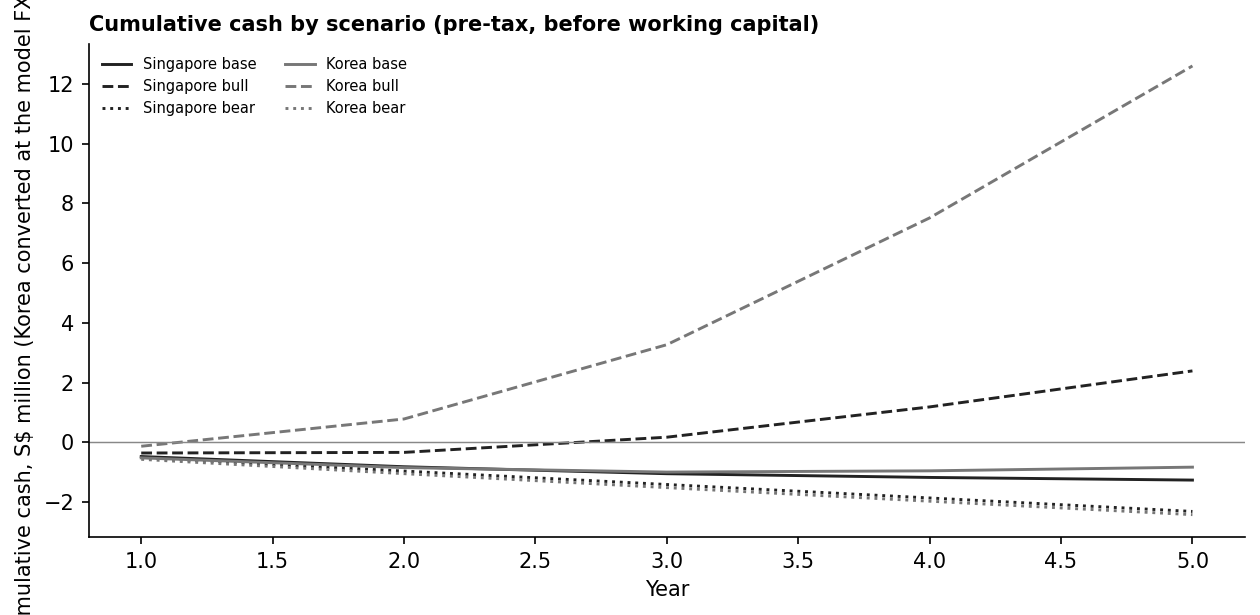

saved CSVs and figures


In [7]:
unit_df.to_csv(HERE / "data" / "fin_unit_economics.csv", index=False)
summary_df.to_csv(HERE / "data" / "fin_scenario_summary.csv", index=False)
pd.concat([cf.assign(market=m, scenario=gc) for (m, gc), cf in flows.items()]).to_csv(HERE / "data" / "fin_cash_flows.csv", index=False)
kpi.to_csv(HERE / "data" / "fin_kpi_test.csv", index=False)
tornado.to_csv(HERE / "data" / "fin_tornado.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), dpi=150, facecolor="white", sharey=False)
for ax, mkt, title in zip(axes, ["singapore", "korea"], ["Singapore", "Korea"]):
    t = tornado[tornado["market"] == mkt].head(8).iloc[::-1]
    base_npv = t["base_npv_sgd"].iloc[0] / 1e6
    lo = t["npv_at_low_sgd"] / 1e6
    hi = t["npv_at_high_sgd"] / 1e6
    y = np.arange(len(t))
    ax.barh(y, lo - base_npv, left=base_npv, color="#8a8a8a", height=0.6, label="low input")
    ax.barh(y, hi - base_npv, left=base_npv, color="#d4d4d4", edgecolor="#333333", linewidth=0.5, height=0.6, label="high input")
    ax.axvline(base_npv, color="#222222", lw=0.8)
    ax.axvline(0, color="#777777", lw=0.8, ls="--")
    ax.set_yticks(y, [s[:34] for s in t["input"]], fontsize=7)
    ax.set_xlabel("NPV, S$ million (5 years plus terminal)", fontsize=8)
    ax.set_title(f"{title}: base NPV S${base_npv:.2f}m", fontsize=9, loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=7, loc="lower right")
fig.text(0.01, 0.01, "Rough inputs from data/assumptions.json. Korea tariff is a placeholder (0 percent base). Dashed line: zero NPV.", fontsize=7, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(HERE / "04_tornado.png", dpi=150, facecolor="white")
plt.show()

fig2, ax2 = plt.subplots(figsize=(8.5, 4.2), dpi=150, facecolor="white")
styles = {"base": "-", "bull": "--", "bear": ":"}
colors = {"singapore": "#222222", "korea": "#777777"}
for (mkt, gc), cf in flows.items():
    fx_to_sgd = 1.0 if mkt == "singapore" else params("korea")["usd_sgd"] / params("korea")["usd_krw"]
    ax2.plot(cf["year"], cf["cum_cash"] * fx_to_sgd / 1e6,
             color=colors[mkt], ls=styles[gc], lw=1.4, label=f"{mkt.title()} {gc}")
ax2.axhline(0, color="#888888", lw=0.7)
ax2.set_xlabel("Year")
ax2.set_ylabel("Cumulative cash, S$ million (Korea converted at the model FX rate)")
ax2.set_title("Cumulative cash by scenario (pre-tax, before working capital)", loc="left", fontsize=10, fontweight="bold")
ax2.legend(frameon=False, fontsize=7, ncol=2)
ax2.spines[["top", "right"]].set_visible(False)
fig2.tight_layout()
fig2.savefig(HERE / "04_cumulative_cash.png", dpi=150, facecolor="white")
plt.show()
print("saved CSVs and figures")

## Reading the outputs

The notebook reproduces the results in `04_financial_model_results.md`. The model is pre-tax and ignores working capital, which is a simplification. Inputs are rough by design, as accepted by the user; the sensitivity table shows which ones move the answer.